# Potential PINN Architecture Comparison Plots

This notebook tests a different question from the CPN shape-optimization notebook. Here the geometry is fixed: all three models predict the RF potential `phi(x, y)` on the same circular Paul-trap domain. The comparison is Vanilla MLP vs PIXEL vs PIG as **potential solvers**, not as coordinate maps.

Each architecture is trained with the same Laplace residual and boundary-condition loss, then evaluated against the circular-trap DEVSIM RF solution. This directly addresses the mentor-requested track: compare field-model architectures by convergence and `phi` MSE versus DEVSIM ground truth.

Why this matters: before optimizing geometry, we need to know which potential representation gives the most accurate and stable electrostatic field. Shape gradients depend on field derivatives, so a weak potential model will make geometry optimization unreliable.

Project TODOs covered by this notebook: implement PIXEL/PIG in their paper-aligned role as scalar potential solvers, compare them fairly against Vanilla, quantify RF potential error against DEVSIM, and decide which architecture is worth carrying into later geometry optimization.

In [1]:
%matplotlib inline
import sys
import importlib
from pathlib import Path
import matplotlib.pyplot as plt

SPINN_ROOT = Path.cwd()
while SPINN_ROOT.name != "SPINN" and SPINN_ROOT != SPINN_ROOT.parent:
    SPINN_ROOT = SPINN_ROOT.parent
if str(SPINN_ROOT) not in sys.path:
    sys.path.insert(0, str(SPINN_ROOT))

from IPython.display import Markdown, display
import experiments.potential_pinn_architectures.config as potential_config
import experiments.potential_pinn_architectures.train as potential_train
import experiments.potential_pinn_architectures.figures as figures

# Jupyter keeps imported modules alive across file edits. Reload the experiment
# modules so this notebook sees fixes without requiring a kernel restart.
importlib.reload(potential_config)
importlib.reload(potential_train)
figures = importlib.reload(figures)

def show(fig):
    display(fig)
    plt.close(fig)

KINDS = ("vanilla", "pixel", "pig")
RUN_TRAINING = True
STEPS = 2000
SKIP_DEVSIM = False

if RUN_TRAINING:
    figures.run_comparison(kinds=KINDS, steps=STEPS, skip_devsim=SKIP_DEVSIM)

figures.available_results(KINDS)


[vanilla]      0 total=4.502e+06 pde=6.943e-04 bc=4.502e+04
[vanilla]    200 total=3.731e+06 pde=3.072e+03 bc=3.728e+04
[vanilla]    400 total=3.120e+06 pde=1.997e+04 bc=3.101e+04
[vanilla]    600 total=2.718e+06 pde=3.701e+04 bc=2.681e+04
[vanilla]    800 total=2.496e+06 pde=7.544e+04 bc=2.421e+04
[vanilla]   1000 total=2.375e+06 pde=1.025e+05 bc=2.272e+04
[vanilla]   1200 total=2.266e+06 pde=1.056e+05 bc=2.160e+04
[vanilla]   1400 total=2.184e+06 pde=1.105e+05 bc=2.073e+04
[vanilla]   1600 total=2.339e+06 pde=3.159e+05 bc=2.023e+04
[vanilla]   1800 total=2.027e+06 pde=7.470e+04 bc=1.953e+04
[pixel]      0 total=4.501e+06 pde=2.891e+01 bc=4.501e+04
[pixel]    200 total=4.391e+06 pde=2.063e+03 bc=4.389e+04
[pixel]    400 total=4.273e+06 pde=6.717e+03 bc=4.266e+04
[pixel]    600 total=4.184e+06 pde=1.011e+04 bc=4.174e+04
[pixel]    800 total=4.110e+06 pde=1.230e+04 bc=4.098e+04
[pixel]   1000 total=4.044e+06 pde=1.418e+04 bc=4.030e+04
[pixel]   1200 total=3.982e+06 pde=1.517e+04 bc=3.96

{'vanilla': True, 'pixel': True, 'pig': True}

**Setup.** This cell optionally trains the selected architectures and reports whether result files exist for each model. A `True` entry means the model has both `training_history.csv` and `comparison_metrics.json`, so the later plots can show convergence and DEVSIM error.

What to check:

- If `RUN_TRAINING=True`, the notebook regenerates results before plotting.
- `SKIP_DEVSIM=False` is required for MSE/error-map plots because those need DEVSIM comparison files.
- The current notebook run uses the step count in `STEPS`; if this is 2000, conclusions are preliminary compared with the intended 5000-step run.

**TODO checked.** Reproducibility gate: can we produce all artifacts needed for a three-way architecture comparison from one notebook or CLI command?

## Convergence

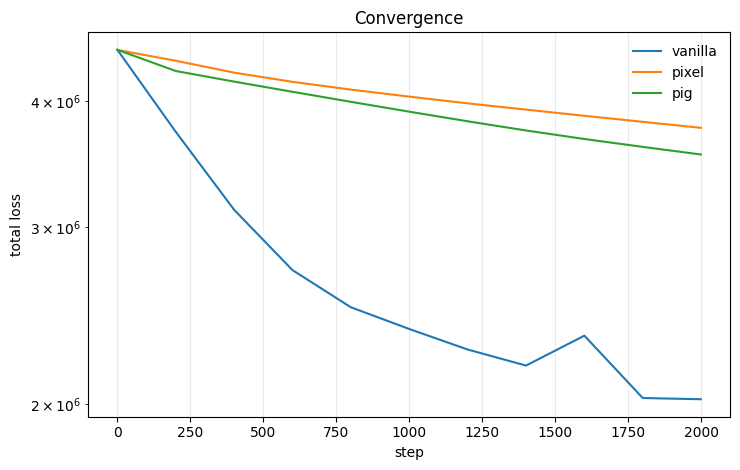

In [2]:
show(figures.plot_convergence(KINDS))


**What the plot shows.** Total training loss for Vanilla, PIXEL, and PIG under the same collocation sampler, boundary sampler, optimizer, learning rate, boundary weight, and step count. Lower loss generally means the model is better satisfying the training objective, but it is not yet a DEVSIM accuracy verdict.

**How it helps.** This separates optimization behavior from final physical accuracy. If one architecture barely reduces loss, it may need different hyperparameters, more capacity, or a different optimizer before a DEVSIM comparison is fair.

**Deduction from the current saved run.** Vanilla falls much faster than PIXEL and PIG over the 2000-step run. PIXEL and PIG do improve, but slowly. This suggests the paper-inspired feature models are not plug-and-play under the Vanilla PINN's Adam settings; they likely need tuning, L-BFGS, or larger paper-scale configurations.

**TODO checked.** Compare convergence across potential architectures. Current answer: *Vanilla converges fastest under this shared first-pass training setup; PIXEL/PIG need tuning before they can be judged as failed architectures*.

## RF Potential MSE vs DEVSIM

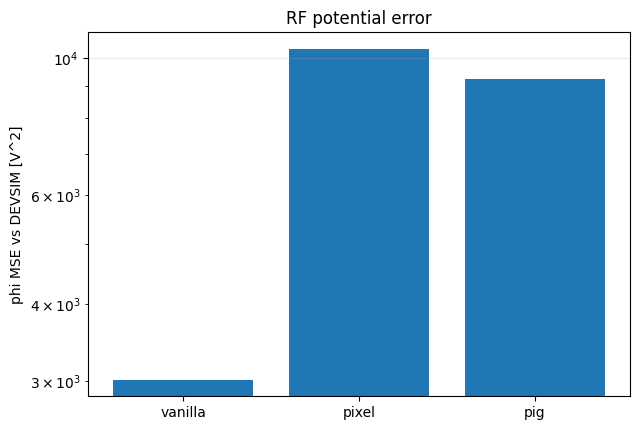

In [3]:
show(figures.plot_phi_mse(KINDS))


**What the plot shows.** A bar chart of RF potential MSE against the DEVSIM mesh-node values. This is the headline architecture metric for the current mentor request: all models predict `phi(x, y)`, and lower MSE means closer agreement with the finite-element reference.

**How it helps.** Training loss can be misleading because it only measures sampled PDE and boundary points. DEVSIM MSE evaluates the learned field on an independent solver's mesh, so it is the first real accuracy gate.

**Deduction from the current saved run.** Vanilla is best in this preliminary 2000-step result: MSE about `3.02e3 V^2`, compared with PIXEL about `1.03e4 V^2` and PIG about `9.25e3 V^2`. PIG is slightly better than PIXEL here, but both trail the Vanilla baseline.

**TODO checked.** Quantify field-model accuracy versus DEVSIM. Current answer: *the first PIXEL/PIG implementation runs end-to-end, but does not yet beat Vanilla under the shared default settings*.

## Metric Table

In [4]:
display(Markdown(figures.metrics_markdown(KINDS)))

| model | phi MSE [V^2] | phi RMSE [V] | phi MAE [V] | MAE / 300 V |
|---|---:|---:|---:|---:|
| vanilla | 3019 | 54.94 | 36.13 | 12.045% |
| pixel | 1.035e+04 | 101.7 | 72.76 | 24.254% |
| pig | 9247 | 96.16 | 67.16 | 22.387% |

**What the table shows.** The numeric DEVSIM comparison behind the bar chart: MSE, RMSE, MAE, and MAE as a percentage of the 300 V RF span.

**How it helps.** The table makes the result portable into slides or reports. RMSE and MAE are easier to interpret physically than MSE: they tell us the typical voltage error. The percentage column normalizes error to the 300 V drive amplitude.

**Deduction from the current saved run.** Vanilla has about `36.1 V` MAE (`12.0%` of 300 V), PIG about `67.2 V` MAE (`22.4%`), and PIXEL about `72.8 V` MAE (`24.3%`). These are not yet competitive with the earlier best fixed-geometry hyperparameter sweep, so this should be treated as a first architecture wiring result, not a final architecture ranking.

## Vanilla Error Map

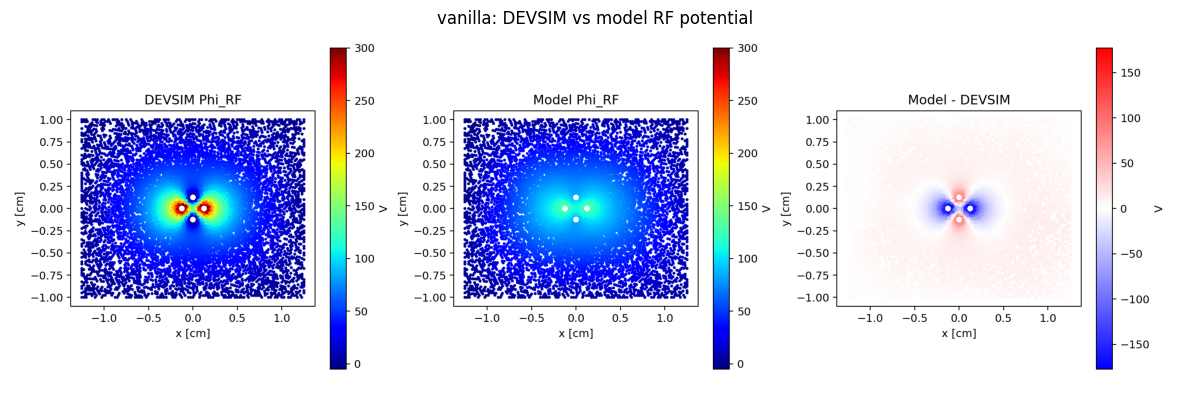

In [5]:
show(figures.show_phi_comparison("vanilla"))


**What the plot shows.** Left: DEVSIM RF potential. Middle: Vanilla MLP prediction. Right: Vanilla minus DEVSIM. Red means the model overpredicts voltage; blue means it underpredicts.

**How it helps.** This reveals *where* the Vanilla baseline is right or wrong. The scalar MSE says Vanilla is best in the current run, but the error map shows that the largest errors are concentrated near the electrode region and central field structure, precisely where field gradients and Hessians matter for trap quality.

**Deduction from the current saved run.** Vanilla captures the broad RF field much better than PIXEL/PIG, but it still smooths out the strongest electrode-localized structure. The error lobes near the center indicate that derivative-sensitive trap metrics may still be imperfect even when voltage MSE is best.

**TODO checked.** Establish the baseline error pattern for the fixed-geometry potential solver before judging alternative architectures.

## PIXEL Error Map

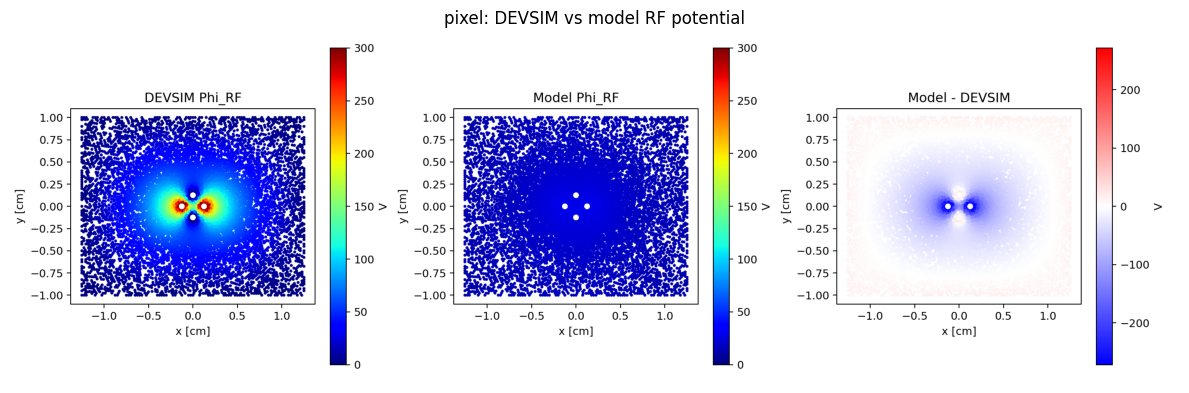

In [6]:
show(figures.show_phi_comparison("pixel"))


**What the plot shows.** Left: DEVSIM RF potential. Middle: PIXEL prediction. Right: PIXEL minus DEVSIM. PIXEL uses local learnable grid features with smooth cosine interpolation, then a scalar potential head.

**How it helps.** PIXEL is supposed to reduce spectral bias by giving local regions their own trainable representation. This error map checks whether that local representation actually captures the sharp electrode-driven field structure better than the Vanilla MLP.

**Deduction from the current saved run.** PIXEL underfits badly: the predicted potential remains too low and too diffuse, with large negative error over the central/electrode region. This does not mean PIXEL is wrong in principle; it means this first configuration and optimizer did not unlock the paper's benefits. Important next knobs are grid resolution, number of multigrids, feature dimension, collocation density, and L-BFGS.

**TODO checked.** Test whether the paper-aligned PIXEL potential architecture is wired correctly and competitive under default settings. Current answer: *wired correctly, not yet competitive*.

## PIG Error Map

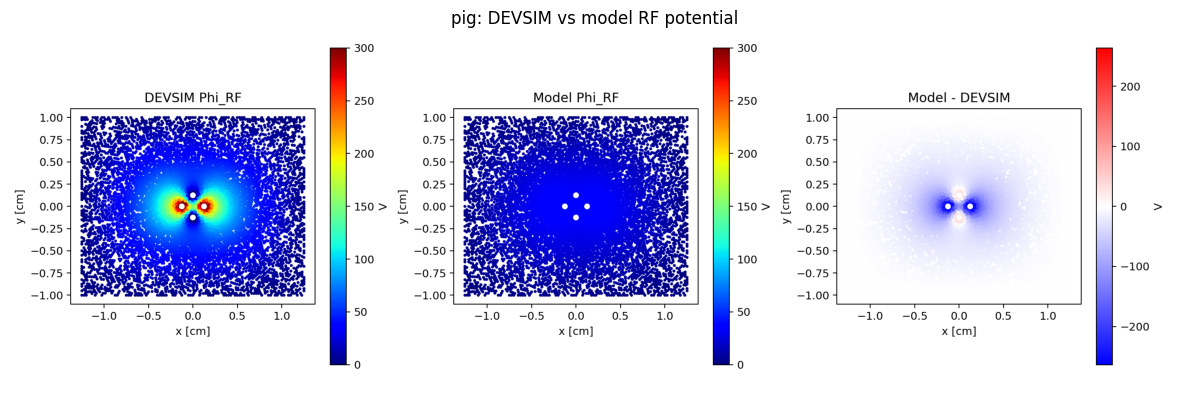

In [7]:
show(figures.show_phi_comparison("pig"))


# Coupled CPN + PINN Shape-Optimization Plots

One plot per cell. The setup cell trains a variation once and returns a
`RunArtifacts` bundle; each later cell calls a single function from `figures.py`
to render one plot, followed by a markdown cell explaining what it shows.

Change `VARIATION` to `"A"` (PINN-first) or `"C"` (joint). The interpretations
below describe the `C` (joint) result, which is the headline case.

**What the plot shows.** Left: DEVSIM RF potential. Middle: PIG prediction. Right: PIG minus DEVSIM. PIG uses trainable Gaussian centers, scales, and features, then a scalar potential head.

**How it helps.** PIG should adapt representational capacity by moving Gaussians toward high-residual or high-frequency regions. The error map tells us whether that adaptive representation is learning the electrode-localized voltage structure.

**Deduction from the current saved run.** PIG is slightly better than PIXEL by MSE/MAE but still underfits the strong central/electrode structure. The model does not yet reproduce the 300 V lobes near the driven electrodes. This suggests either the run is too short, the Gaussian count/configuration is too small relative to the paper-scale setup, or Adam alone is not enough.

**TODO checked.** Test whether the paper-aligned PIG potential architecture can run and be compared against DEVSIM. Current answer: *yes, the pipeline works; accuracy is not yet strong enough to replace Vanilla without more tuning*.

**Overall conclusion.** This notebook now ticks off the architecture-comparison plumbing: Vanilla, PIXEL, and PIG all train as scalar potential solvers and produce DEVSIM metrics. The scientific conclusion from the current run is conservative: Vanilla is the best first-pass baseline, while PIXEL/PIG remain promising but require paper-scale hyperparameter/optimizer tuning before they can be fairly promoted into the shape-optimization loop.